# Sinh nội dung marketing thời trang nữ bằng GenAI
**Nguyễn Quang Minh** · Lớp HKC2026-CDNK-26C1EXT60901501 · GV: TS. Võ Văn Hải

Nghiên cứu dùng CRISP-DM để khảo sát đặc trưng nội dung liên quan đến bán chạy, so sánh các phương pháp sinh và đánh giá nội dung. Các quan hệ quan sát không chứng minh nhân quả.

**Liên kết:** mã nguồn https://github.com/minhnguyen66690-source/genai-marketing-thoi-trang-nu; website demo: WEB_URL (điền sau khi triển khai).

**Mục lục:** 1. Cài đặt · 2. Thu thập · 3. Tiền xử lý · 4. EDA · 5. Mô tả · 6. RQ1 · 7. Từ khóa · 8. Phản đối · 9. Sinh nội dung · 10. LoRA · 11. Đánh giá · 12. Đề xuất · 13. Công cụ AI · 14. Tài liệu.

## 1. Cài đặt
Các cờ mặc định tắt vì thu thập, sinh, tinh chỉnh và chấm tốn thời gian, API hoặc GPU. Khi tắt, notebook đọc kết quả công khai đã lưu. Trên Colab cần điền URL repo trước khi chạy.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/minhnguyen66690-source/genai-marketing-thoi-trang-nu'
WEB_URL = 'https://genai-thoitrangnu.streamlit.app'
if IN_COLAB:
    if not REPO_URL:
        raise ValueError('Hãy điền REPO_URL trước khi chạy trên Colab.')
    repo_dir = Path('/content') / REPO_URL.rstrip('/').split('/')[-1].removesuffix('.git')
    if not repo_dir.exists():
        subprocess.run(['git', 'clone', REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-colab.txt'], check=True)
    ROOT = repo_dir
    from google.colab import userdata
    for key in ('GEMINI_API_KEY', 'OPENAI_API_KEY'):
        try:
            value = userdata.get(key)
            if value: os.environ[key] = value
        except Exception:
            pass  # Không in khóa hoặc lỗi có thể chứa khóa.
else:
    here = Path.cwd().resolve()
    ROOT = here.parent if here.name == 'notebook' else here
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
RUN_CRAWL = RUN_GENERATION = RUN_FINETUNE = RUN_JUDGE = False
N_ITER = 2  # Tăng số lần tìm kiếm khi chạy nghiên cứu đầy đủ.
PUBLIC = ROOT / 'results/public'
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
def read_json(path):
    if not path.exists():
        print('chưa có kết quả:', path.name)
        return {}
    with open(path, encoding='utf-8-sig') as f: return json.load(f)

## 2. Thu thập dữ liệu — hiểu dữ liệu
Giới hạn thu thập Tiki ở một yêu cầu mỗi giây, dừng khi bị chặn; review được ẩn danh và không xuất nội dung gốc. Dữ liệu Amazon Reviews 2023 là nguồn đối chiếu công khai.

In [2]:
# Chỉ thu thập khi đã chủ động bật cờ.
if RUN_CRAWL:
    subprocess.run([sys.executable, 'src/crawl_tiki.py', '--smoke'], check=True)
    subprocess.run([sys.executable, 'src/fetch_amazon2023.py', '--smoke'], check=True)
feature_path = ROOT / 'data/processed/tiki_features.csv'
if IN_COLAB or not feature_path.exists(): feature_path = ROOT / 'data/public/tiki_features_public.csv'
df = pd.read_csv(feature_path) if feature_path.exists() else pd.DataFrame()
print('Nguồn đặc trưng:', feature_path.relative_to(ROOT), '| số dòng:', len(df))

Nguồn đặc trưng: data\processed\tiki_features.csv | số dòng: 1941


## 3. Tiền xử lý và phễu lọc
Chuẩn hóa văn bản, loại mô tả quá ngắn và bản ghi trùng; nhãn bán chạy được xếp trong từng danh mục. Bảng dưới đây lấy từ kết quả đã lưu.

In [3]:
funnel = read_json(PUBLIC / 'data_funnel.json')
stages = ['raw_valid', 'within_7y', 'description_at_least_50', 'deduplicated']
display(pd.DataFrame([{'Bước': k, 'Số sản phẩm': funnel[k]} for k in stages if k in funnel]))

,Bước,Số sản phẩm
0,raw_valid,2181
1,within_7y,2021
2,description_at_least_50,1979
3,deduplicated,1941


## 4. Phân tích khám phá
Biểu đồ tỷ lệ dùng khoảng tin cậy Wilson 95%; nhóm số gạch đầu dòng được phân chia thành không có và có ít nhất một.

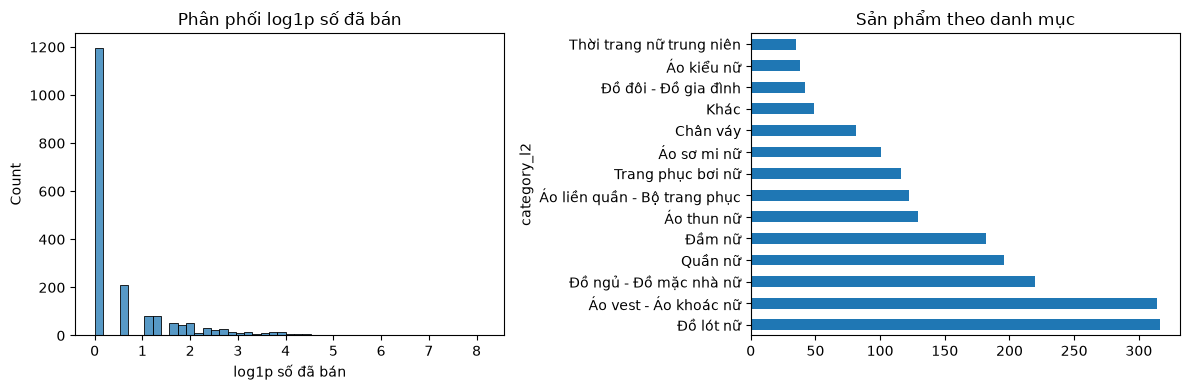

In [4]:
if not df.empty:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(np.log1p(pd.to_numeric(df.quantity_sold, errors='coerce').clip(lower=0)), ax=ax[0])
    ax[0].set(title='Phân phối log1p số đã bán', xlabel='log1p số đã bán')
    df.category_l2.value_counts().plot.barh(ax=ax[1], title='Sản phẩm theo danh mục')
    plt.tight_layout(); plt.show()
else: print('chưa có kết quả: dữ liệu đặc trưng')

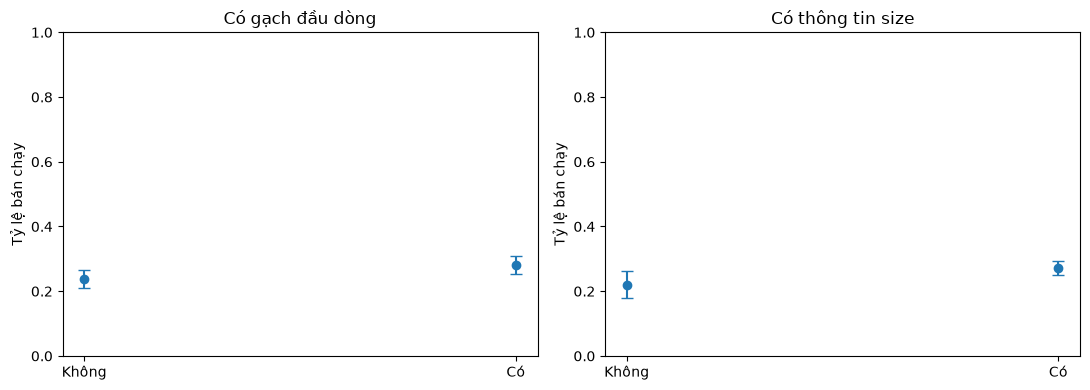

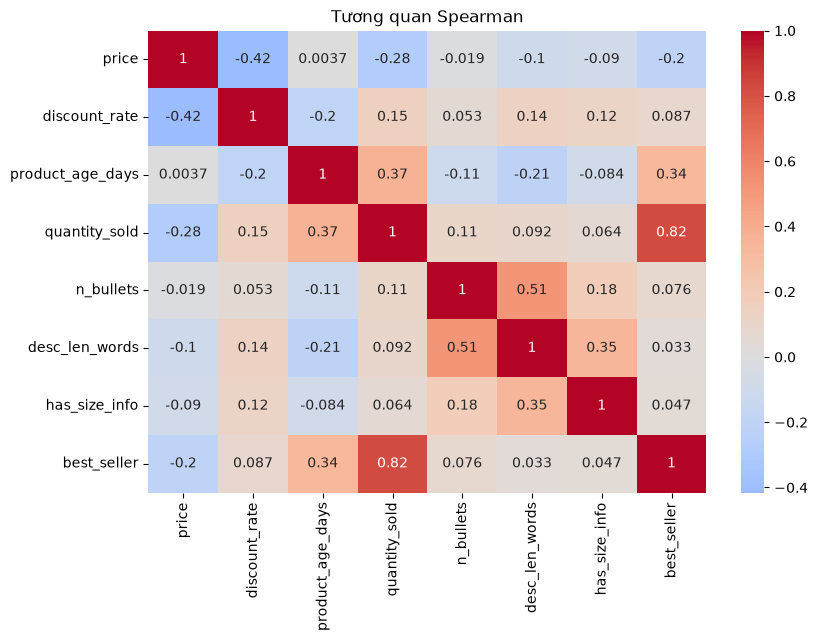

In [5]:
from statsmodels.stats.proportion import proportion_confint
if not df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, col, label in zip(axes, ['n_bullets', 'has_size_info'], ['Có gạch đầu dòng', 'Có thông tin size']):
        group = df.assign(nhom=pd.to_numeric(df[col], errors='coerce').fillna(0).gt(0)).groupby('nhom').best_seller.agg(['sum', 'count'])
        p = group['sum'] / group['count']
        lo, hi = proportion_confint(group['sum'], group['count'], method='wilson')
        ax.errorbar(range(len(p)), p, yerr=[p-lo, hi-p], fmt='o', capsize=4)
        ax.set_xticks(range(len(p)), ['Có' if x else 'Không' for x in group.index]); ax.set(title=label, ylabel='Tỷ lệ bán chạy', ylim=(0, 1))
    plt.tight_layout(); plt.show()
    cols = ['price', 'discount_rate', 'product_age_days', 'quantity_sold', 'n_bullets', 'desc_len_words', 'has_size_info', 'best_seller']
    plt.figure(figsize=(9, 6)); sns.heatmap(df[cols].corr(method='spearman', numeric_only=True), annot=True, cmap='coolwarm', center=0); plt.title('Tương quan Spearman'); plt.show()

## 5. Phân tích mô tả
Các biến chính được tóm tắt theo phân phối và trung vị theo nhãn bán chạy.

In [6]:
if not df.empty:
    main_cols = ['price', 'discount_rate', 'quantity_sold', 'product_age_days', 'desc_len_words', 'n_bullets']
    display(df[main_cols].describe().T)
    display(df.groupby('best_seller')[main_cols].median())

,count,mean,std,min,25%,50%,75%,max
price,1941.0,389378.281813,547217.797353,3500.0,146700.0,225000.0,400000.0,5890000.0
discount_rate,1941.0,3.825863,9.269925,0.0,0.0,0.0,0.0,52.0
quantity_sold,1941.0,8.336425,90.615141,0.0,0.0,0.0,2.0,3546.0
product_age_days,1941.0,1379.078310,662.483106,12.0,749.0,1519.0,1947.0,2549.0
desc_len_words,1941.0,203.887687,146.307288,12.0,84.0,166.0,298.0,878.0
n_bullets,1941.0,4.892324,6.731006,0.0,0.0,2.0,7.0,36.0


,price,discount_rate,quantity_sold,product_age_days,desc_len_words,n_bullets
best_seller,,,,,,
0,249000.0,0.0,0.0,1311.0,167.0,2.0
1,189250.0,0.0,6.0,1839.0,164.0,3.0


## 6. Dự báo RQ1
Chia train/test phân tầng, chọn siêu tham số bằng CV trên train. Không đưa số đã bán, số đánh giá hoặc điểm đánh giá vào mô hình. Ablation giữ cùng thuật toán; chọn theo AUC CV, không chọn theo test.

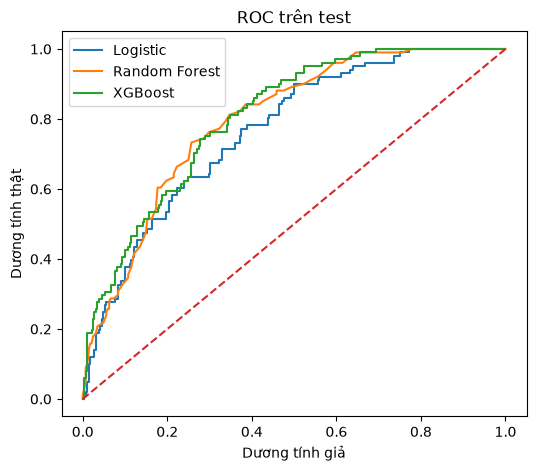

,Mô hình,AUC CV,ROC-AUC test,PR-AUC,F1
0,Logistic,0.802553,0.766158,0.504994,0.525180
1,Random Forest,0.814960,0.797545,0.549613,0.567442
2,XGBoost,0.807945,0.805831,0.578569,0.516484


In [7]:
from predictive import prepare, pipeline, CONTROL, CONTENT
# common.py chọn backend ghi ảnh; khôi phục backend inline để hiện biểu đồ notebook.
plt.switch_backend('module://matplotlib_inline.backend_inline')
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, roc_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from scipy.stats import loguniform, randint
scores, fitted = [], {}
if not df.empty and df.best_seller.nunique() == 2 and df.best_seller.value_counts().min() >= 7:
    d = prepare(df); y = d.best_seller.astype(int)
    X = d[CONTROL + CONTENT + ['category_l2']]
    xt, xv, yt, yv = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
    cv = StratifiedKFold(n_splits=min(3, int(yt.value_counts().min())), shuffle=True, random_state=42)
    models = {
        'Logistic': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'model__C': loguniform(.01, 10)}),
        'Random Forest': (RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=1), {'model__n_estimators': randint(30, 80), 'model__max_depth': [4, 8, None]}),
        'XGBoost': (XGBClassifier(n_jobs=1, random_state=42, eval_metric='logloss'), {'model__n_estimators': randint(30, 80), 'model__max_depth': randint(2, 5)})}
    fig, ax = plt.subplots(figsize=(6, 5))
    for name, (est, params) in models.items():
        search = RandomizedSearchCV(pipeline(est, CONTROL + CONTENT), params, n_iter=N_ITER, scoring='roc_auc', cv=cv, random_state=42, n_jobs=1)
        search.fit(xt, yt); fitted[name] = search
        prob = search.predict_proba(xv)[:, 1]
        scores.append({'Mô hình': name, 'AUC CV': search.best_score_, 'ROC-AUC test': roc_auc_score(yv, prob), 'PR-AUC': average_precision_score(yv, prob), 'F1': f1_score(yv, search.predict(xv), zero_division=0)})
        fpr, tpr, _ = roc_curve(yv, prob); ax.plot(fpr, tpr, label=name)
    ax.plot([0, 1], [0, 1], '--'); ax.set(xlabel='Dương tính giả', ylabel='Dương tính thật', title='ROC trên test'); ax.legend(); plt.show()
    display(pd.DataFrame(scores))
else: print('chưa có kết quả: không đủ dữ liệu hai lớp')

In [8]:
if fitted:
    best = max(fitted, key=lambda name: fitted[name].best_score_)
    est, params = models[best]
    control = RandomizedSearchCV(pipeline(est, CONTROL), params, n_iter=N_ITER, scoring='roc_auc', cv=cv, random_state=42, n_jobs=1).fit(xt, yt)
    display(pd.DataFrame([{'Mô hình chọn theo CV': best, 'Chỉ kiểm soát': roc_auc_score(yv, control.predict_proba(xv)[:, 1]), 'Thêm nội dung': roc_auc_score(yv, fitted[best].predict_proba(xv)[:, 1])}]))
    imp = permutation_importance(fitted[best], xv, yv, scoring='roc_auc', n_repeats=3, random_state=42, n_jobs=1)
    display(pd.DataFrame({'Biến': X.columns, 'Giảm AUC': imp.importances_mean}).sort_values('Giảm AUC', ascending=False).head(15))

,Mô hình chọn theo CV,Chỉ kiểm soát,Thêm nội dung
0,Random Forest,0.78596,0.797545


,Biến,Giảm AUC
2,product_age_days,0.147890
0,log_price,0.048777
4,n_options,0.010697
11,n_sentences,0.005781
1,discount_rate,0.004383
3,n_images,0.002905
12,avg_sentence_len_words,0.002802
6,title_len_words,0.002137
9,n_paragraphs,0.002097
19,has_cta,0.001851


In [9]:
# OR là liên hệ có kiểm soát, không phải hiệu ứng nhân quả.
if not df.empty:
    try:
        import statsmodels.api as sm
        from statsmodels.stats.multitest import multipletests
        from rq1_inference import build_design, CONTENT_CONTINUOUS, CONTENT_BINARY
        design = build_design(df)
        fit = sm.Logit(df.best_seller.astype(int), design).fit(disp=False, maxiter=200)
        ci = fit.conf_int()
        table = pd.DataFrame({'OR': np.exp(fit.params), 'CI thấp': np.exp(ci[0]), 'CI cao': np.exp(ci[1]), 'p': fit.pvalues})
        # Hiệu chỉnh Holm cho họ kiểm định gồm 9 đặc trưng nội dung.
        content = [c for c in table.index if c in CONTENT_CONTINUOUS or c in CONTENT_BINARY]
        table.loc[content, 'p Holm'] = multipletests(table.loc[content, 'p'], method='holm')[1]
        display(table)
    except (ValueError, np.linalg.LinAlgError) as exc:
        print('chưa có kết quả Logit:', type(exc).__name__)

,OR,CI thấp,CI cao,p,p Holm
const,0.032489,0.001257,0.839439,3.888002e-02,NaN
desc_len_words,1.090048,0.857431,1.385772,4.814179e-01,1.000000
n_bullets,1.218113,1.042738,1.422984,1.286028e-02,0.102882
n_paragraphs,1.030172,0.824674,1.286877,7.934301e-01,1.000000
title_len_chars,1.287242,1.121535,1.477433,3.290348e-04,0.002961
uppercase_ratio,1.040262,0.908544,1.191077,5.676965e-01,1.000000
has_size_info,0.980681,0.695208,1.383377,9.115057e-01,1.000000
has_material_info,1.263740,0.801555,1.992426,3.136017e-01,1.000000
has_care_info,0.911883,0.669637,1.241764,5.582018e-01,1.000000
has_cta,0.748346,0.531491,1.053682,9.682394e-02,0.677768


## 7. Từ khóa đặc trưng
Thuật toán 1 tách cụm từ trong tên, loại từ chung và mã hàng, đếm tần suất theo sản phẩm, chọn cụm đủ phổ biến và cụ thể; tách train/test trước khi dùng trong sinh. Dữ liệu công khai chỉ chứa từ khóa tổng hợp.

In [10]:
if not IN_COLAB and 'name' in df.columns:
    from keywords import name_segments, candidate_phrases, select_keywords
    from collections import Counter
    phrases = [candidate_phrases(name_segments(r['name'], r.get('brand', ''), 'vi'), 'vi') for _, r in df.iterrows()]
    counts = Counter(p for group in phrases for p in group)
    chosen = [select_keywords(group, counts, len(df), 'vi') for group in phrases]
    keyword_result = {}
    for cat, indices in df.reset_index(drop=True).groupby('category_l2').groups.items():
        top = Counter(term for i in indices for term in chosen[i]).most_common(5)
        keyword_result[cat] = {'top_keywords': [{'keyword': term, 'count': count} for term, count in top]}
    print('Đã trích lại từ tên sản phẩm cục bộ.')
else:
    keyword_result = read_json(PUBLIC / 'keywords_by_category.json').get('tiki', {})
categories = keyword_result.get('categories', keyword_result)
keyword_rows = [{'Danh mục': cat, **item} for cat, obj in categories.items() if isinstance(obj, dict) for item in obj.get('top_keywords', [])[:5]]
display(pd.DataFrame(keyword_rows))

C:\Users\Minh\NgoaiKhoa_work\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đã trích lại từ tên sản phẩm cục bộ.


,Danh mục,keyword,count
0,Chân váy,chân váy,57
1,Chân váy,chữ,10
2,Chân váy,xòe,8
3,Chân váy,ngắn,8
4,Chân váy,chân,7
...,...,...,...
65,Đồ đôi - Đồ gia đình,mr,27
66,Đồ đôi - Đồ gia đình,buffalo,25
67,Đồ đôi - Đồ gia đình,áo đôi,18
68,Đồ đôi - Đồ gia đình,lỡ,15


## 8. Phản đối của khách hàng
Bảng là số đếm theo chủ đề, không chứa nội dung review.

In [11]:
obj = read_json(ROOT / 'data/public/objection_themes_summary.json')
display(pd.DataFrame.from_dict(obj.get('by_category', {}), orient='index'))

,n_low_reviews,Size không vừa,Không giống hình/mô tả,Chất liệu kém,Màu sắc khác,"Đường may, lỗi sản phẩm","Giao hàng, đóng gói"
Chân váy,16,0,3,3,0,1,2
Quần nữ,26,3,2,2,0,4,1
Thời trang nữ trung niên,2,0,1,0,1,0,0
Trang phục bơi nữ,33,4,5,5,4,0,2
Áo kiểu nữ,6,1,0,3,0,1,0
Áo liền quần - Bộ trang phục,3,0,0,0,0,1,1
Áo sơ mi nữ,16,2,4,2,1,1,1
Áo thun nữ,4,1,1,0,0,0,2
Áo vest - Áo khoác nữ,56,1,18,7,2,1,5
Đầm nữ,19,0,4,1,0,1,1


## 9. Sinh nội dung
M1 zero-shot; M2 thêm ràng buộc; M3 thêm ví dụ truy hồi. Ví dụ minh họa dưới đây là dữ liệu giả lập; kết quả đã sinh được đọc riêng từ tệp công khai.

In [12]:
from prompts import zero_shot, engineered, fewshot_retrieval
brief = {'item_id': 'demo', 'category': 'Áo nữ', 'keywords': ['áo linen'], 'attributes': {'Chất liệu': 'linen'}, 'objections': []}
for name, prompt in [('M1', zero_shot([brief])), ('M2', engineered([brief])), ('M3', fewshot_retrieval([brief], {'demo': [{'brief': brief, 'description': 'Áo linen có phom dáng đơn giản.'}]}))]:
    print('\n', name, '\n', prompt)
if RUN_GENERATION:
    from llm_api import generate_via_api
    key = os.environ.get('GEMINI_API_KEY')
    if key:
        inputs = pd.read_csv(ROOT / 'data/public/gen_inputs_tiki_public.csv').head(2)
        for _, row in inputs.iterrows():
            b = {'item_id': str(row.product_id), 'category': row.category_l2, 'keywords': json.loads(row.keywords), 'attributes': json.loads(row.attributes)}
            print(generate_via_api(engineered([b]), 'gemini', key)[0])
    else: print('chưa có kết quả: thiếu GEMINI_API_KEY')


 M1 
 Bạn là người viết nội dung cho một cửa hàng thời trang nữ trên sàn thương mại điện tử.
Với mỗi sản phẩm trong brief, hãy viết: tiêu đề sản phẩm, đoạn mô tả meta, bài mô tả sản phẩm, kịch bản chốt sale (tin nhắn tư vấn gửi khách hàng) và 3 tiêu đề email marketing.
ĐỊNH DẠNG ĐẦU RA: chỉ trả về một mảng JSON hợp lệ, không giải thích, không markdown. Mỗi phần tử ứng với một sản phẩm và có đúng các khóa: item_id (giữ nguyên như brief), title, meta_description, description, sales_script, email_subjects (mảng gồm 3 chuỗi).

BRIEF:
[
 {
  "item_id": "demo",
  "category": "Áo nữ",
  "keywords": [
   "áo linen"
  ],
  "attributes": {
   "Chất liệu": "linen"
  },
  "objections": []
 }
]

 M2 
 Nhiệm vụ: viết nội dung bán hàng cho các sản phẩm thời trang nữ trong brief.
YÊU CẦU:
- VAI TRÒ: bạn là copywriter thương mại điện tử chuyên thời trang nữ, viết tiếng Việt tự nhiên, đúng chính tả.
- TỪ KHÓA CHÍNH: là từ khóa đầu tiên trong danh sách keywords của từng sản phẩm.
- DỮ KIỆN: chỉ dùng thô

In [13]:
def show_generations(methods):
    for method in methods:
        paths = sorted((PUBLIC / 'generations').glob('generations_' + method + '_*.jsonl'))
        if not paths:
            print(method, ': chưa có kết quả'); continue
        path = next((p for p in paths if p.name.endswith('_tiki.jsonl')), paths[0])
        with open(path, encoding='utf-8-sig') as f:
            records = [json.loads(line) for line in f if line.strip()][:2]
        print(method, '—', path.name)
        for record in records: display(record.get('output', {}))
show_generations(['M0', 'M1', 'M2', 'M3'])

M0 — generations_M0_tiki.jsonl


{'title': 'áo ngực áo bra dây - Đồ lót nữ',
 'meta_description': 'áo ngực - Đồ lót nữ. áo bra, dây, trễ vai.',
 'description': 'Áo ngực thuộc danh mục Đồ lót nữ.\nĐặc điểm nổi bật: áo ngực, áo bra, dây, trễ vai, tính, áo trễ.\nThông tin sản phẩm: Xuất xứ: China / Vietnam.\nSản phẩm phù hợp nhiều dịp sử dụng hằng ngày.\nVui lòng liên hệ cửa hàng để được tư vấn chọn size.',
 'sales_script': 'Chào chị, mẫu áo ngực bên em hiện vẫn còn hàng ạ. Chị cho em xin chiều cao và cân nặng để em tư vấn size phù hợp nhé. Chị đặt hàng ngay để nhận sản phẩm sớm ạ!',
 'email_subjects': ['áo ngực - mẫu mới',
  'Khám phá áo ngực',
  'Đồ lót nữ: gợi ý cho bạn']}

{'title': 'áo khoát dễ thương jean - Áo vest - Áo khoác nữ',
 'meta_description': 'áo khoát - Áo vest - Áo khoác nữ. dễ thương, jean.',
 'description': 'Áo khoát thuộc danh mục Áo vest - Áo khoác nữ.\nĐặc điểm nổi bật: áo khoát, dễ thương, jean.\nThông tin sản phẩm: Xuất xứ: Việt Nam; Màu sắc: Xanh nhạt, Xanh đậm; Kích cỡ: L(55-64kg), M(45-54kg), XL(65-74kg).\nSản phẩm phù hợp nhiều dịp sử dụng hằng ngày.\nVui lòng liên hệ cửa hàng để được tư vấn chọn size.',
 'sales_script': 'Chào chị, mẫu áo khoát bên em hiện vẫn còn hàng ạ. Chị cho em xin chiều cao và cân nặng để em tư vấn size phù hợp nhé. Chị đặt hàng ngay để nhận sản phẩm sớm ạ!',
 'email_subjects': ['áo khoát - mẫu mới',
  'Khám phá áo khoát',
  'Áo vest - Áo khoác nữ: gợi ý cho bạn']}

M1 — generations_M1_tiki.jsonl


{'title': 'Áo bra nữ có dây phối áo trễ vai',
 'meta_description': 'Áo bra nữ có dây, gợi ý phối cùng áo trễ vai. Liên hệ shop để xem ảnh, tư vấn kiểu dáng, kích cỡ và thông tin giao hàng.',
 'description': 'Áo bra nữ có dây là lựa chọn để bạn tham khảo khi phối cùng trang phục trễ vai. Xuất xứ theo thông tin sản phẩm: Trung Quốc hoặc Việt Nam. Trước khi đặt hàng, bạn hãy nhắn shop để được gửi ảnh sản phẩm, xác nhận xuất xứ và tư vấn kích cỡ phù hợp.',
 'sales_script': 'Dạ, chị đang tìm áo bra mặc cùng áo trễ vai phải không ạ? Shop có thể gửi chị ảnh sản phẩm và tư vấn kiểu dây, kích cỡ trước khi đặt. Chị cho shop xin số đo vòng ngực và khu vực nhận hàng để shop kiểm tra thông tin sản phẩm, cách đóng gói và thời gian giao dự kiến nhé.',
 'email_subjects': ['Áo bra có dây cho những set đồ trễ vai',
  'Tìm áo bra phối cùng áo trễ vai? Xem ngay',
  'Nhắn shop chọn áo bra phù hợp với bạn']}

{'title': 'Áo khoác jean nữ dễ thương màu xanh nhạt, xanh đậm',
 'meta_description': 'Áo khoác jean nữ xuất xứ Việt Nam, có hai màu xanh nhạt và xanh đậm, size M đến XL. Nhắn shop xem ảnh và tư vấn size.',
 'description': 'Áo khoác jean nữ mang đến gợi ý phối đồ dễ thương cho những ngày đi học, đi chơi hoặc dạo phố.\n\nSản phẩm có hai màu xanh nhạt và xanh đậm, xuất xứ Việt Nam. Size tham khảo theo cân nặng: M 45–54 kg, L 55–64 kg, XL 65–74 kg. Để chọn size phù hợp hơn, bạn hãy gửi chiều cao và số đo cho shop. Shop cũng có thể cung cấp thêm ảnh và thông tin về chất liệu trước khi bạn đặt hàng.',
 'sales_script': 'Dạ, mẫu áo khoác jean này có màu xanh nhạt và xanh đậm, size M, L, XL chị nhé. Chị cho shop xin chiều cao, cân nặng và số đo để tư vấn size phù hợp ạ. Nếu chị muốn xem kỹ màu áo và chất liệu, shop sẽ gửi thêm thông tin, hình ảnh để chị tham khảo trước khi đặt.',
 'email_subjects': ['Áo khoác jean dễ thương cho ngày xuống phố',
  'Xanh nhạt hay xanh đậm: bạn chọn màu nào?',
  '

... (2 outputs left out)

{'title': 'áo khoát jean nữ dễ thương với hai màu xanh',
 'meta_description': 'áo khoát jean nữ dễ thương có hai màu xanh nhạt, xanh đậm và các size M, L, XL. Mời bạn xem sản phẩm nhé!',
 'description': 'áo khoát jean là lựa chọn dễ phối khi bạn muốn thêm một lớp áo ngoài cho trang phục hằng ngày. Với hai màu xanh nhạt và xanh đậm, sản phẩm mang đến những lựa chọn để bạn kết hợp theo sở thích và tủ đồ của mình.\n\nBạn có thể thử phối áo cùng quần dài và áo thun cho buổi đi chơi, hoặc kết hợp với chân váy để tạo vẻ ngoài dễ thương. Chỉ cần thay đổi món đồ mặc bên trong và phụ kiện, bạn đã có thêm nhiều cách diện cho những dịp gặp gỡ bạn bè hay dạo phố.\n\nMột số thông tin và gợi ý để bạn lựa chọn:\n- Màu xanh nhạt và xanh đậm giúp bạn dễ chọn theo sở thích phối đồ.\n- Size M dành cho khoảng 45–54 kg, size L khoảng 55–64 kg và size XL khoảng 65–74 kg.\n- Phối cùng áo thun và quần dài khi bạn muốn một bộ đồ thuận tiện cho hoạt động thường ngày.\n- Kết hợp cùng chân váy để thử phong cách d

M3 — generations_M3_tiki.jsonl


{'title': 'áo ngực nữ phối đồ cùng trang phục trễ vai xinh xắn',
 'meta_description': 'áo ngực nữ là lựa chọn để bạn tham khảo khi phối đồ thường ngày hoặc diện trang phục trễ vai nữ tính. Mời bạn xem sản phẩm nhé!',
 'description': 'áo ngực là món đồ cơ bản giúp bạn hoàn thiện trang phục từ bên trong, dù bạn đang chuẩn bị đi làm, dạo phố hay gặp gỡ bạn bè. Nếu yêu thích những bộ cánh trễ vai, bạn có thể tham khảo mẫu áo bra này và chọn cách phối phù hợp với trang phục của mình.\n\nMột chiếc áo lót vừa vặn sẽ giúp bạn yên tâm hơn khi mặc cả ngày. Trước khi chọn, bạn nên cân nhắc kiểu trang phục thường diện và sở thích cá nhân về độ ôm. Với áo trễ vai, hãy thử phối trước để kiểm tra phần dây có phù hợp với cách mặc mà bạn mong muốn hay không.\n\n- Gợi ý phối đồ: diện cùng áo trễ vai và chân váy cho buổi hẹn nhẹ nhàng, nữ tính.\n- Dịp sử dụng: tham khảo để mặc cùng trang phục đi làm, đi chơi hoặc dạo phố tùy cách phối.\n- Cách chọn size: đo vòng chân ngực và vòng ngực, sau đó đối chiếu s

{'title': 'áo khoát jean nữ dễ thương với hai màu xanh xinh',
 'meta_description': 'áo khoát jean nữ có hai màu xanh nhạt và xanh đậm, dễ phối cùng trang phục đi chơi hay dạo phố. Mời bạn xem sản phẩm nhé!',
 'description': 'áo khoát jean nữ là gợi ý dành cho bạn yêu thích cách phối đồ trẻ trung và dễ thương. Với hai lựa chọn xanh nhạt, xanh đậm, bạn có thể chọn màu phù hợp với những món đồ thường mặc và tạo nên bộ trang phục theo phong cách riêng.\n\nMột chiếc áo khoác jean có thể kết hợp cùng áo thun và quần dài cho những buổi đi học, gặp bạn bè hoặc dạo phố. Nếu thích vẻ nữ tính hơn, bạn thử phối cùng chân váy và một đôi giày phù hợp với lịch trình trong ngày nhé.\n\n- Màu sắc: xanh nhạt và xanh đậm để bạn lựa chọn theo sở thích.\n- Size M: tham khảo cho cân nặng khoảng 45–54 kg.\n- Size L: tham khảo cho cân nặng khoảng 55–64 kg.\n- Size XL: tham khảo cho cân nặng khoảng 65–74 kg.\n- Xuất xứ: Việt Nam.\n\nBảng cân nặng giúp bạn chọn size ban đầu; chiều cao, số đo cơ thể và sở thích 

## 10. Tinh chỉnh LoRA
Mặc định dùng tập Amazon đã tiền xử lý và GPU; quá trình có thể tải mô hình và cần thời gian. Khi chưa chạy, xem log và đầu ra đã lưu.

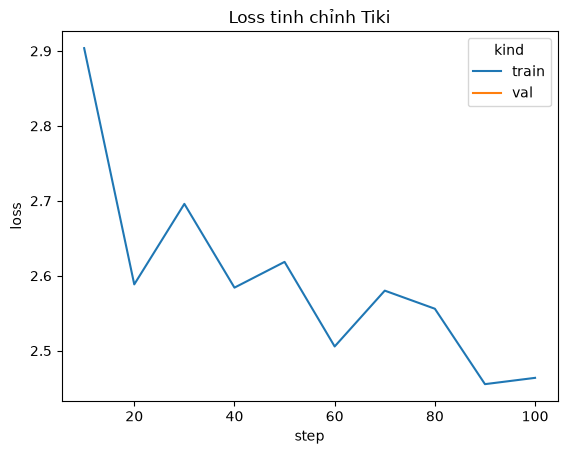

M4a — generations_M4a_tiki.jsonl


{'title': 'Mô tả sản phẩm thời trang nữ:',
 'meta_description': '',
 'description': 'Mô tả sản phẩm thời trang nữ:\n\nDưới đây là một gợi ý về cách viết mô tả sản phẩm thời trang nữ theo yêu cầu bạn cung cấp:\n\n"Chắc chắn không thể bỏ qua những chiếc áo ngực, áo bra và dây đẹp mắt này! Chúng mang lại sự thoải mái cho cả ngày dài, giúp bạn tự tin hơn trong các buổi họp mặt hoặc đi chơi. Dù bạn chọn từ nước ngoài hay Việt Nam, chúng đều được thiết kế với chất liệu tốt, tạo ra cảm giác mềm mại và dễ chịu. Đặc biệt, chúng còn phù hợp với nhiều kiểu dáng khác nhau, từ áo sơ mi đến quần jeans, giúp bạn có thể kết hợp mọi outfit của mình. Hãy thử ngay để sở hữu một bộ đồ lót nữ hoàn hảo nhất!"',
 'sales_script': '',
 'email_subjects': []}

{'title': 'Dưới đây là một mô tả ngắn về sản phẩm thời trang nữ với các đặc điểm bạn đã cung cấp:',
 'meta_description': '',
 'description': 'Dưới đây là một mô tả ngắn về sản phẩm thời trang nữ với các đặc điểm bạn đã cung cấp:\n\n"Áo khoác nữ từ chất liệu jean mềm mại và áo khoát dễ thương, phù hợp với mọi loại身材. Sản phẩm có kích thước L (55-64kg) và M (45-54kg), giúp bạn thoải mái mặc trong nhiều tình huống khác nhau. Đặc biệt, chúng tôi cung cấp màu sắc xanh nhạt và xanh đậm để tạo ra sự đa dạng cho lựa chọn của bạn."',
 'sales_script': '',
 'email_subjects': []}

M4b — generations_M4b_tiki.jsonl


{'title': '- Áo Trễ Vai Bra 2018',
 'meta_description': '',
 'description': '- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018\n- Áo Trễ Vai Bra 2018',
 'sales_script': '',
 'email_subjects': []}

{'title': 'Áo khoác nữ áo khoát jean 2018',
 'meta_description': '',
 'description': 'Áo khoác nữ áo khoát jean 2018\nChất liệu: 90% cotton, 10% polyester\nSize: L (55-64kg)\nM (45-54kg)\nXL (65-74kg)\nThiết kế: Chất liệu áo khoác nữ có thể mặc trong nhiều loại quần áo khác nhau như quần jeans, quần lụa, quần áo đi bộ, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi, quần áo đi chơi,

In [14]:
import torch
if RUN_FINETUNE and torch.cuda.is_available():
    subprocess.run([sys.executable, 'src/finetune_lora.py', '--dataset', 'amazon', '--train', '--generate'], check=True)
elif RUN_FINETUNE: print('chưa có kết quả: cần GPU')
loss_path = PUBLIC / 'finetune_tiki.csv'
if loss_path.exists():
    loss = pd.read_csv(loss_path)
    if not loss.empty:
        sns.lineplot(data=loss, x='step', y='loss', hue='kind'); plt.title('Loss tinh chỉnh Tiki'); plt.show()
else: print('chưa có kết quả: loss')
show_generations(['M4a', 'M4b'])

### 10b. Thử cách sinh chữ và siêu tham số cho mô hình nhỏ
Chạy trên CPU bằng src/ft_sweep.py, đánh giá trên 10 sản phẩm của tập kiểm định. Hai dòng đầu dùng cùng adapter M4b, chỉ khác cách sinh chữ; các dòng sau huấn luyện lại 40 bước với hạng LoRA (r) và tốc độ học (lr) khác.

In [15]:
sweep = read_json(PUBLIC / 'ft_sweep.json')
if sweep:
    display(pd.DataFrame(sweep).drop(columns=['sample', 'decode'], errors='ignore'))
else:
    print('chưa có kết quả: ft_sweep.json')

,config,val_loss,n_eval,pct_repetitive,mean_latency_s,mean_words,r,lr,steps,train_minutes
0,M4b_giai_ma_cu,2.550,10,100.0,32.5,199.2,16,0.00020,100,NaN
1,M4b_chan_lap_3tu,2.550,10,0.0,27.4,152.7,16,0.00020,100,NaN
2,r8_lr1e-4,2.802,10,0.0,26.4,154.4,8,0.00010,40,43.5
3,r16_lr5e-5,2.815,10,0.0,55.0,159.0,16,0.00005,40,40.4
4,r16_lr1e-4,2.762,10,0.0,21.1,137.3,16,0.00010,40,286.7


## 11. Đánh giá
ROUGE-L, chrF++ và BERTScore so với tham chiếu; checklist và tỷ lệ thuộc tính không có căn cứ là thước đo theo luật, không thay thế kiểm duyệt. Các ngưỡng S../E.. ánh xạ trong `src/evaluate.py` và `_workspace/01_research/verified_refs.md`; proxy được ghi rõ trong mã. Wilcoxon đã hiệu chỉnh Holm lấy từ kết quả lưu.

,rougeL,chrf_plus_plus,bertscore_f1,seo_compliance_rate,hallucination_rate,latency_s,judge_mo_ta_tu_nhien,judge_mo_ta_lien_quan_tu_khoa,judge_mo_ta_thuyet_phuc,judge_mo_ta_nhat_quan_thong_tin,...,judge_kich_ban_nhu_cau_loi_ich,judge_kich_ban_xu_ly_phan_doi,judge_kich_ban_dung_su_that,email_mailchimp_le9w_le60c,email_omnisend_4_6w_or_21_40c,email_punct_le3,email_emoji_le1,email_no_fake_re_fwd,email_keyword_relevance,email_offer_supported
method,,,,,,,,,,,,,,,,,,,,,
M0,0.106128,12.752602,0.647693,0.566155,0.003472,0.000027,1.973154,4.583893,1.966443,4.791946,...,1.959732,1.248322,3.308725,0.917226,0.765101,1.0,1.0,1.0,0.771812,1.0
M1,0.111366,12.944056,0.636278,0.538671,0.052994,6.526954,4.805369,4.530201,3.932886,5.000000,...,3.261745,3.563758,5.000000,0.693512,0.677852,1.0,1.0,1.0,0.861298,1.0
M2,0.094965,19.304242,0.621614,0.836529,0.096106,13.279578,4.939597,3.724832,4.134228,4.946309,...,4.261745,4.456376,4.966443,1.000000,0.997763,1.0,1.0,1.0,0.982103,1.0
M3,0.097341,19.759809,0.622654,0.876318,0.076628,13.999803,4.912752,3.946309,4.060403,4.953020,...,4.194631,4.315436,4.959732,1.000000,0.997763,1.0,1.0,1.0,0.988814,1.0
M4a,0.108316,15.935211,0.642023,0.291525,0.172348,17.278792,2.135593,3.101695,1.966102,2.305085,...,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
M4b,0.071584,11.229052,0.567215,0.596610,0.622075,34.939620,1.169492,2.830508,1.372881,1.627119,...,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reference,NaN,NaN,NaN,0.558725,0.705047,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


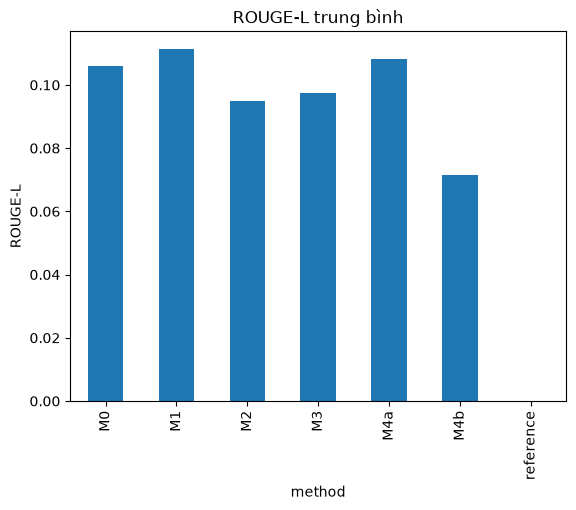

eval_summary_amazon.json — Wilcoxon/Holm


,metric,method_a,method_b,n_pairs,p,p_holm
0,seo_compliance_rate,M0,M1,50,1.835155e-03,2.605921e-01
1,seo_compliance_rate,M0,M2,50,4.752534e-10,1.078825e-07
2,seo_compliance_rate,M0,M3,50,3.065434e-10,7.050498e-08
3,seo_compliance_rate,M0,reference,50,6.886961e-05,1.088140e-02
4,seo_compliance_rate,M1,M2,50,8.449359e-10,1.799713e-07
...,...,...,...,...,...,...
246,email_offer_supported,M0,M2,50,1.000000e+00,1.000000e+00
247,email_offer_supported,M0,M3,50,1.000000e+00,1.000000e+00
248,email_offer_supported,M1,M2,50,1.000000e+00,1.000000e+00
249,email_offer_supported,M1,M3,50,1.000000e+00,1.000000e+00


eval_summary_tiki.json — Wilcoxon/Holm


,metric,method_a,method_b,n_pairs,p,p_holm
0,seo_compliance_rate,M0,M1,99,6.403224e-01,1.000000e+00
1,seo_compliance_rate,M0,M2,99,1.830234e-18,1.004798e-15
2,seo_compliance_rate,M0,M3,99,2.404646e-18,1.315341e-15
3,seo_compliance_rate,M0,M4a,59,1.685128e-10,6.336082e-08
4,seo_compliance_rate,M0,M4b,59,1.270747e-01,1.000000e+00
...,...,...,...,...,...,...
565,email_offer_supported,M0,M2,99,1.000000e+00,1.000000e+00
566,email_offer_supported,M0,M3,99,1.000000e+00,1.000000e+00
567,email_offer_supported,M1,M2,99,1.000000e+00,1.000000e+00
568,email_offer_supported,M1,M3,99,1.000000e+00,1.000000e+00


,Loại,Tiêu chí,Nguồn
0,SEO,title_len_50_60,S19
1,SEO,title_tiki_15_50,S23
2,SEO,title_tiki_max_225,S23
3,SEO,meta_len_120_156,S12
4,SEO,keyphrase_in_title,S11
5,SEO,keyphrase_in_first_paragraph,S10
6,SEO,keyphrase_in_meta,S11
7,SEO,density_proxy_0_5_3,S09 proxy
8,SEO,desc_words_ge_200,S13/S24
9,Email,mailchimp_le9w_le60c,E01


In [16]:
if RUN_JUDGE:
    print('Để chấm lại, chạy src/evaluate.py với dữ liệu đầu vào và backend phù hợp; cần API.')
eval_files = sorted(PUBLIC.glob('eval_per_item_*.csv'))
summary_files = sorted(PUBLIC.glob('eval_summary_*.json'))
evaluation = pd.concat([pd.read_csv(p).assign(nguon=p.name) for p in eval_files], ignore_index=True) if eval_files else pd.DataFrame()
if evaluation.empty: print('chưa có kết quả: đánh giá theo sản phẩm')
else:
    metrics = [c for c in ['rougeL', 'chrf_plus_plus', 'bertscore_f1', 'seo_compliance_rate', 'hallucination_rate', 'latency_s'] if c in evaluation]
    metrics += [c for c in evaluation if c.startswith(('email_', 'judge_')) and pd.api.types.is_numeric_dtype(evaluation[c])]
    comparison = evaluation.groupby('method')[metrics].mean(numeric_only=True)
    display(comparison)
    if 'rougeL' in comparison:
        comparison['rougeL'].plot.bar(title='ROUGE-L trung bình'); plt.ylabel('ROUGE-L'); plt.show()
for path in summary_files:
    result = read_json(path)
    print(path.name, '— Wilcoxon/Holm'); display(pd.DataFrame(result.get('wilcoxon_holm', [])))
if not summary_files: print('chưa có kết quả: Wilcoxon')
from evaluate import SEO_LABELS, EMAIL_LABELS
display(pd.DataFrame([{'Loại': kind, 'Tiêu chí': k, 'Nguồn': v} for kind, labels in [('SEO', SEO_LABELS), ('Email', EMAIL_LABELS)] for k, v in labels.items()]))

### 11b. Kiểm tra độ vững
Prompt v2 được sửa sau khi xem lỗi trên tập kiểm tra, nên M0, M2, M3 được chạy lại trên 40 sản phẩm của tập kiểm định chưa dùng khi sửa prompt. Bảng dưới so sánh cùng một bộ chỉ số trên hai tập; tiếp theo là tỷ lệ tuân thủ trên năm tiêu chí chung (bỏ hai tiêu chí meta mà nội dung người bán không có) và độ chính xác, độ phủ ROUGE-L.

In [17]:
holdout = read_json(PUBLIC / 'holdout_check.json')
if holdout:
    display(pd.DataFrame([{'Tập': split, 'Cấu hình': m, **v} for split in ('val', 'test') for m, v in holdout.get(split, {}).items()]))
extra = read_json(PUBLIC / 'extra_checks.json')
if extra:
    display(pd.DataFrame(extra.get('seo_common_5', {})).rename_axis('Cấu hình'))
    display(pd.DataFrame(extra.get('rougeL_precision_recall', {}).get('tiki', {})).T)
else:
    print('chưa có kết quả kiểm tra độ vững')

,Tập,Cấu hình,n,seo_compliance_7,seo_common_5,email_mailchimp,objection_theme_coverage,unsupported_claims,unsupported_rate,prompt_leakage
0,val,M0,40,61.1,65.5,88.3,9.0,1/144,0.7,0.0
1,val,M2,40,91.1,91.5,100.0,100.0,6/185,3.2,0.0
2,val,M3,40,86.4,90.0,100.0,100.0,7/191,3.7,0.0
3,test,M0,99,58.4,61.8,87.5,12.4,1/249,0.4,0.0
4,test,M2,99,81.0,85.1,100.0,100.0,11/261,4.2,0.0
5,test,M3,99,85.4,86.3,100.0,100.0,9/283,3.2,0.0


,tiki,amazon
Cấu hình,,
M0,61.8,54.5
M1,59.2,41.5
M2,85.1,85.0
M3,86.3,89.5
M4a,29.2,NaN
M4b,59.7,NaN
reference,64.6,38.5


,n,precision,recall,median_length_ratio_gen_over_ref
M0,99.0,0.224,0.107,0.42
M1,99.0,0.194,0.116,0.51
M2,99.0,0.091,0.165,1.88
M3,99.0,0.093,0.171,1.93
M4a,59.0,0.142,0.121,0.88
M4b,59.0,0.076,0.099,1.48


## 12. Phân tích đề xuất
Chọn cấu hình theo từng chỉ số thực đo. Độ trễ nhân 100 là ước tính tuần tự, không bao gồm kiểm duyệt; các chỉ số thiếu không được suy diễn.

In [18]:
if not evaluation.empty:
    for metric, higher in [('rougeL', True), ('chrf_plus_plus', True), ('bertscore_f1', True), ('seo_compliance_rate', True), ('hallucination_rate', False), ('latency_s', False)]:
        if metric in comparison and comparison[metric].notna().any():
            s = comparison[metric].dropna(); method = s.idxmax() if higher else s.idxmin()
            print(metric, ':', method, '=', s.loc[method])
    if 'latency_s' in comparison: display((comparison['latency_s'] * 100).rename('Giây cho 100 sản phẩm, tuần tự'))
else: print('chưa có kết quả: chưa thể chọn cấu hình')
print('Quy trình: kiểm tra brief → sinh → người duyệt dữ kiện, giọng điệu và chính sách → chỉnh sửa → đăng.')

rougeL : M1 = 0.1113657177006209
chrf_plus_plus : M3 = 19.759809236503774
bertscore_f1 : M0 = 0.647693085590465
seo_compliance_rate : M3 = 0.8763183125599234
hallucination_rate : M0 = 0.003472222222222222
latency_s : M0 = 2.6855033505877915e-05


method
M0              0.002686
M1            652.695353
M2           1327.957757
M3           1399.980267
M4a          1727.879161
M4b          3493.961988
reference            NaN
Name: Giây cho 100 sản phẩm, tuần tự, dtype: float64

Quy trình: kiểm tra brief → sinh → người duyệt dữ kiện, giọng điệu và chính sách → chỉnh sửa → đăng.


### 12b. Chi phí và thời gian cho một shop
Số token đếm thật trên 99 sản phẩm của M2 (src/token_usage.py, bộ tách token o200k_base, ước lượng). Giá công bố, truy cập 14/11/2026: Gemini 3.8 Flash 0,75/3,75 USD mỗi triệu token vào/ra (Google AI Studio, giá áp dụng đến 31/12/2026); gpt-6.1-terra 1/5 USD (OpenAI). Quy đổi làm tròn 26.000 đồng/USD là giả định để dễ hình dung, không phải tỷ giá chính thức.

In [19]:
tok = read_json(PUBLIC / 'token_usage.json')
if tok:
    price = {'Gemini 3.8 Flash': (0.75, 3.75), 'gpt-6.1-terra': (1.0, 5.0)}
    rows = []
    for model, (p_in, p_out) in price.items():
        usd = (tok['input_tokens_mean'] * p_in + tok['output_tokens_mean'] * p_out) / 1e6
        rows.append({'Mô hình': model, 'USD/sản phẩm': round(usd, 5), 'Đồng/sản phẩm (26.000 đ/USD)': round(usd * 26000),
                     'Đồng cho 50 mẫu/tháng': round(usd * 26000 * 50)})
    display(pd.DataFrame(rows))
    print('Thời gian máy viết 50 mẫu:', round(50 * tok['latency_s_mean'] / 60, 1), 'phút')
else:
    print('chưa có kết quả: token_usage.json')

,Mô hình,USD/sản phẩm,Đồng/sản phẩm (26.000 đ/USD),Đồng cho 50 mẫu/tháng
0,Gemini 3.8 Flash,0.00307,80,3985
1,gpt-6.1-terra,0.00409,106,5313


Thời gian máy viết 50 mẫu: 11.8 phút


## 13. Công cụ AI được sử dụng
| Công cụ | Vai trò được khai báo |
|---|---|
| Claude Opus 5.5 qua Claude Code | Điều phối, viết bài, kiểm chứng |
| GPT-6.1-Terra / GPT-6.1-Sol qua Codex CLI | Viết code, tra cứu, sinh nội dung M1–M3 |
| Gemini 3.8 Flash qua Antigravity CLI | Giám khảo LLM chính |
| GPT-5.6-Luna qua Codex CLI | Giám khảo thứ hai, chỉ dùng đo đồng thuận |
| Claude Haiku và Sonnet | Kiểm chứng trích dẫn, dựng slide |
| Qwen2.5-0.5B-Instruct | Mô hình tinh chỉnh LoRA |
| bert-base-multilingual-cased | BERTScore |

Vai trò ghi theo nhật ký thực hiện của tác giả; mọi số liệu được tính bằng mã nguồn trong kho, không lấy từ câu trả lời của mô hình.

## 14. Tài liệu tham khảo chính
- Hou, Y., et al. (2024). *Bridging language and items for retrieval and recommendation*. Amazon Reviews 2023.
- Google. *Search Central: Creating helpful, reliable, people-first content*. https://developers.google.com/search/docs/fundamentals/creating-helpful-content
- Hu, E. J., et al. (2022). *LoRA: Low-rank adaptation of large language models*. https://arxiv.org/abs/2106.09685
- Zhang, T., et al. (2020). *BERTScore: Evaluating text generation with BERT*. https://arxiv.org/abs/1904.09675
- Nguồn chi tiết các tiêu chí: `_workspace/01_research/verified_refs.md`.